# W11 — Asset-History BI: Controlled Experiment (FD001)

**Question.** Can the framework exploit business data *when that data genuinely carries information about lifetime*, and does such data make sense in a real industrial setting?

**Background.** W10 showed that, once leakage is removed, operational BI (costs, schedules, resources) does not improve RUL accuracy: it carries no information about degradation. This notebook tests a different category of enterprise data: **asset history**, recorded in ERP traceability and CMMS maintenance logs.

| Variable | Type | Source | Real-world motivation |
|---|---|---|---|
| `component_batch` | categorical (B1–B8) | ERP traceability | Production-lot defects (e.g. 2023 PW1100G powder-metal HPT disks) |
| `supplier` | binary (OEM / alternative) | ERP purchasing | Part quality varies by supplier |
| `last_overhaul_type` | binary (light / full) | CMMS | A full overhaul restores more life |
| `prior_unplanned_removals` | count | CMMS | "Bad actor" engines fail repeatedly |
| `hours_since_overhaul_entry` | continuous (h) | CMMS | Engines entering service with more hours are more worn |

All five are **static**: known when the engine enters service, joined to sensors on `unit` only.

**Design.** The link to lifetime is simulated with a controlled strength ρ ∈ {0, 0.2, 0.4, 0.6} (see `src/generate_bi_asset_data.py`). ρ = 0 is pure noise.

**Protocol (no contact with the official test set).**
- Only `train_FD001.txt` (100 run-to-failure engines) is used. `test_FD001.txt` and `RUL_FD001.txt` are never read.
- 5-fold cross-validation **by engine** (GroupKFold).
- Each held-out engine is truncated at 3 random points (as NASA built the official test set); the model predicts RUL from the last window.
- Model: XGBoost branch (`MLBranch`, statistics flattening, W = 30, RUL cap 125), identical to W10.

**Configurations.**

| Code | Features |
|---|---|
| S | Sensors + settings |
| S+Op | Sensors + operational BI (W10 variables) |
| S+A(ρ) | Sensors + asset history at strength ρ |
| S+A~(ρ) | Sensors + asset history **shuffled across engines** (falsification control) |
| S+Op+A(ρ) | Full framework |

**Test battery.** Section 3 (realism), Section 4 (leakage), Sections 6–7 (falsification and mechanism), Section 8 (automatic verdict).

## 0. Setup

In [1]:
import os, sys, subprocess
from pathlib import Path
from datetime import datetime

IN_COLAB = 'COLAB_GPU' in os.environ or os.path.exists('/content')

if IN_COLAB:
    # Fresh clone every run, so the latest code and data are always used
    if os.path.exists('/content/PhD-Project-'):
        !rm -rf /content/PhD-Project-
    !git clone https://github.com/f-khadija-benzine/PhD-Project-.git /content/PhD-Project-
    !pip install xgboost -q
    os.chdir('/content/PhD-Project-/src')
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = Path('/content/PhD-Project-')
    TIMESTAMP = datetime.now().strftime('%Y%m%d_%H%M')
    SAVE_DIR = Path(f'/content/drive/MyDrive/PhD_results/W11_{TIMESTAMP}')
else:
    PROJECT_ROOT = Path('.').resolve().parent if Path('.').resolve().name == 'notebooks' else Path('.').resolve()
    SAVE_DIR = None

sys.path.insert(0, str(PROJECT_ROOT / 'src'))
sys.path.insert(0, str(PROJECT_ROOT))

CMAPSS_DIR = PROJECT_ROOT / 'data' / 'raw_data' / 'C_MAPSS'
BI_DIR     = PROJECT_ROOT / 'data' / 'raw_data' / 'BI_data'
ASSET_DIR  = BI_DIR / 'asset'
RESULTS_W11 = PROJECT_ROOT / 'results' / 'W11_asset_history'
RESULTS_W11.mkdir(parents=True, exist_ok=True)
if SAVE_DIR is not None:
    SAVE_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Results:      {RESULTS_W11}")
print(f"Drive save:   {SAVE_DIR}")

Project root: /home/claude/f-khadija-benzine/phd-project-
Results:      /home/claude/f-khadija-benzine/phd-project-/results/W11_asset_history
Drive save:   None


In [2]:
# Regenerate both BI blocks from the generators in the repo, so data and code always match
for script in ['generate_bi_data.py', 'generate_bi_asset_data.py']:
    res = subprocess.run([sys.executable, str(PROJECT_ROOT / 'src' / script)],
                         capture_output=True, text=True, cwd=str(PROJECT_ROOT))
    print(f"--- {script} ---")
    print(res.stdout[-1500:])
    if res.returncode != 0:
        print(res.stderr[-2000:])
        raise RuntimeError(f"{script} failed")

--- generate_bi_data.py ---
  Train: 100 units, cycles [128, 362]
  Test:  100 units, observed cycles [31, 303]
  Train BI: BI_FD001_train.csv — (20631, 15)
  Test BI:  BI_FD001_test.csv — (13096, 15)
  PM=501, CM=3802, Ratio=7.6x
  Within-unit Spearman rho with RUL (mean over units):
    downtime_penalty       +0.012
    production_priority    +0.012
    cm_cost                +0.157
    pm_cost                -0.088
    revenue_per_hour       -0.070

Generating BI data for FD002
  Skipping FD002: C-MAPSS train file not found: /home/claude/f-khadija-benzine/phd-project-/data/raw_data/C_MAPSS/train_FD002.txt
Expected in: /home/claude/f-khadija-benzine/phd-project-/data/raw_data/C_MAPSS

Generating BI data for FD003
  Skipping FD003: C-MAPSS train file not found: /home/claude/f-khadija-benzine/phd-project-/data/raw_data/C_MAPSS/train_FD003.txt
Expected in: /home/claude/f-khadija-benzine/phd-project-/data/raw_data/C_MAPSS

Generating BI data for FD004
  Skipping FD004: C-MAPSS train file

--- generate_bi_asset_data.py ---
C-MAPSS: /home/claude/f-khadija-benzine/phd-project-/data/raw_data/C_MAPSS
Output:  /home/claude/f-khadija-benzine/phd-project-/data/raw_data/BI_data/asset
  BI_FD001_asset_rho00.csv: (100, 6)
  BI_FD001_asset_rho02.csv: (100, 6)
  BI_FD001_asset_rho04.csv: (100, 6)
  BI_FD001_asset_rho06.csv: (100, 6)
  BI_FD001_asset_audit.csv: audit only (never used as a feature)
✓ Done.



In [3]:
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import RidgeCV
import warnings
warnings.filterwarnings('ignore')

import ml_branch, bi_fusion, generate_bi_asset_data as gba
for m in (ml_branch, bi_fusion, gba):
    importlib.reload(m)
from ml_branch import MLBranch
from bi_fusion import CATEGORICAL_BI_VARS, CONTINUOUS_BI_VARS, BI_FEATURE_NAMES

SEED = 42
RUL_MAX = 125
WINDOW = 30
N_FOLDS = 5
N_CUTS = 3                       # truncation points per held-out engine
RHOS = gba.RHO_LEVELS            # [0.0, 0.2, 0.4, 0.6]
ASSET_VARS = gba.ASSET_VARS

# Set QUICK = True for a fast smoke test (fewer trees). Use False for the reported results.
QUICK = False
XGB_PARAMS = {'n_estimators': 80, 'max_depth': 4} if QUICK else {}

np.random.seed(SEED)
plt.style.use('seaborn-v0_8-whitegrid')
print("Imports ✓  | QUICK =", QUICK)

Imports ✓  | QUICK = False


## 1. Load data (training engines only)

In [4]:
cols = ['unit', 'cycle'] + [f'setting_{i}' for i in range(1, 4)] + [f'sensor_{i}' for i in range(1, 22)]
train = pd.read_csv(CMAPSS_DIR / 'train_FD001.txt', sep=r'\s+', header=None, names=cols, engine='python')
train['total_life'] = train.groupby('unit')['cycle'].transform('max')
train['rul'] = train['total_life'] - train['cycle']

SENSOR_COLS = [c for c in train.columns if c.startswith(('sensor_', 'setting_'))]
UNITS = np.sort(train['unit'].unique())
LIFE = train.groupby('unit')['total_life'].first()

# Operational BI (W10 variables, v2 generator) — training engines only
bi_op = pd.read_csv(BI_DIR / 'BI_FD001_train.csv').rename(columns={'unit_id': 'unit'})

# Asset-history BI, one file per rho
asset = {rho: pd.read_csv(ASSET_DIR / f"BI_FD001_asset_{gba.rho_tag(rho)}.csv").rename(columns={'unit_id': 'unit'})
         for rho in RHOS}
audit = pd.read_csv(ASSET_DIR / 'BI_FD001_asset_audit.csv').rename(columns={'unit_id': 'unit'})

print(f"Train sensors: {train.shape}, {len(UNITS)} engines, life [{LIFE.min()}, {LIFE.max()}]")
print(f"Operational BI: {bi_op.shape}")
for rho in RHOS:
    print(f"Asset BI rho={rho}: {asset[rho].shape}")
asset[0.4].head()

Train sensors: (20631, 28), 100 engines, life [128, 362]
Operational BI: (20631, 15)
Asset BI rho=0.0: (100, 6)
Asset BI rho=0.2: (100, 6)
Asset BI rho=0.4: (100, 6)
Asset BI rho=0.6: (100, 6)


,unit,component_batch,supplier,last_overhaul_type,prior_unplanned_removals,hours_since_overhaul_entry
0,1,B5,1,1,1,1206.0
1,2,B7,0,0,2,528.0
2,3,B2,0,0,2,1399.0
3,4,B7,0,0,0,1073.0
4,5,B7,1,1,0,1457.0


## 2. Shuffled control and truncation plan

- **Shuffled asset data:** the asset rows are permuted across engines (one fixed permutation). Each engine receives another engine's history, which keeps the distribution identical but breaks the link to its own lifetime.
- **Truncation plan:** fixed once, so every configuration is evaluated on exactly the same points (paired comparison). Cut points are drawn uniformly between 10% and 95% of each engine's life.

In [5]:
rng = np.random.default_rng(SEED)
PERM = rng.permutation(len(UNITS))
asset_shuf = {}
for rho in RHOS:
    a = asset[rho].sort_values('unit').reset_index(drop=True)
    s = a.copy()
    s[ASSET_VARS] = a[ASSET_VARS].values[PERM]
    asset_shuf[rho] = s

cut_rows = []
for u in UNITS:
    life = int(LIFE[u])
    lo, hi = max(int(0.10 * life), 1), max(int(0.95 * life), 2)
    for k, c in enumerate(np.sort(rng.integers(lo, hi, N_CUTS))):
        cut_rows.append({'unit': u, 'cut_id': k, 'cut_cycle': int(c),
                         'true_rul': min(life - int(c), RUL_MAX)})
CUTS = pd.DataFrame(cut_rows)

folds = list(GroupKFold(n_splits=N_FOLDS).split(UNITS, groups=UNITS))
print(f"{len(CUTS)} evaluation points ({N_CUTS} per engine); true RUL range {CUTS.true_rul.min()}–{CUTS.true_rul.max()}")
print("Fold sizes (test engines):", [len(te) for _, te in folds])

300 evaluation points (3 per engine); true RUL range 9–125
Fold sizes (test engines): [20, 20, 20, 20, 20]


## 3. Realism checks

Does the simulated asset history look like a plausible fleet record?

- **R1** Marginal distributions in plausible ranges.
- **R2** No batch separates engines perfectly: life ranges of the best and worst batches overlap.
- **R3** Effect sizes are moderate: best/worst batch median-life ratio ≤ 1.5; group differences by supplier and overhaul type ≤ 30%.

In [6]:
realism = []
for rho in RHOS:
    a = asset[rho].merge(LIFE.rename('life'), left_on='unit', right_index=True)
    med_b = a.groupby('component_batch')['life'].median()
    worst, best = med_b.idxmin(), med_b.idxmax()
    overlap = a.loc[a.component_batch == worst, 'life'].max() > a.loc[a.component_batch == best, 'life'].min()
    sup = a.groupby('supplier')['life'].median()
    ovh = a.groupby('last_overhaul_type')['life'].median()
    realism.append({
        'rho': rho,
        'alt_supplier_%': 100 * a.supplier.mean(),
        'full_overhaul_%': 100 * a.last_overhaul_type.mean(),
        'removals_mean': a.prior_unplanned_removals.mean(),
        'hours_median': a.hours_since_overhaul_entry.median(),
        'batch_ratio_best_worst': med_b.max() / med_b.min(),
        'batches_overlap': overlap,
        'supplier_diff_%': 100 * abs(sup.get(0, np.nan) - sup.get(1, np.nan)) / sup.mean(),
        'overhaul_diff_%': 100 * abs(ovh.get(1, np.nan) - ovh.get(0, np.nan)) / ovh.mean(),
    })
realism_df = pd.DataFrame(realism).round(2)
display(realism_df)

R1 = realism_df.apply(lambda r: 25 <= r['alt_supplier_%'] <= 55 and 35 <= r['full_overhaul_%'] <= 70
                      and 0.4 <= r['removals_mean'] <= 1.6 and 500 <= r['hours_median'] <= 2500, axis=1).all()
R2 = realism_df['batches_overlap'].all()
R3 = (realism_df['batch_ratio_best_worst'] <= 1.5).all() and \
     (realism_df[['supplier_diff_%', 'overhaul_diff_%']] <= 30).all().all()
print(f"R1 plausible distributions: {R1} | R2 batches overlap: {R2} | R3 moderate effect sizes: {R3}")

,rho,alt_supplier_%,full_overhaul_%,removals_mean,hours_median,batch_ratio_best_worst,batches_overlap,supplier_diff_%,overhaul_diff_%
0,0.0,38.0,54.0,1.05,1184.5,1.33,True,6.45,2.78
1,0.2,40.0,54.0,1.01,1161.5,1.18,True,0.00,4.04
2,0.4,37.0,56.0,1.00,1178.0,1.21,True,3.56,6.57
3,0.6,35.0,57.0,1.02,1124.5,1.32,True,4.58,9.62


R1 plausible distributions: True | R2 batches overlap: True | R3 moderate effect sizes: True


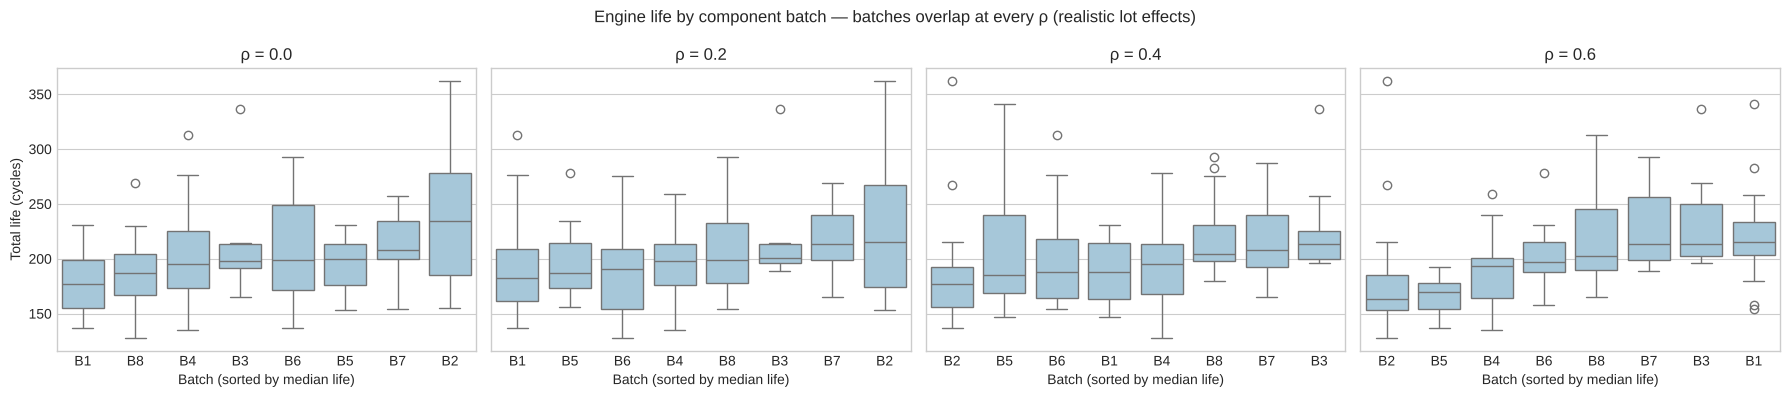

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, rho in zip(axes, RHOS):
    a = asset[rho].merge(LIFE.rename('life'), left_on='unit', right_index=True)
    order = a.groupby('component_batch')['life'].median().sort_values().index
    sns.boxplot(data=a, x='component_batch', y='life', order=order, ax=ax, color='#9ecae1')
    ax.set_title(f"ρ = {rho}")
    ax.set_xlabel('Batch (sorted by median life)')
axes[0].set_ylabel('Total life (cycles)')
fig.suptitle('Engine life by component batch — batches overlap at every ρ (realistic lot effects)')
plt.tight_layout()
plt.savefig(RESULTS_W11 / 'fig_life_by_batch.png', dpi=150)
plt.show()

## 4. Leakage checks

- **L1** Asset variables are constant within each engine (static records, no cycle-by-cycle dependence on degradation).
- **L2** The asset generator never opens the test file or the RUL ground-truth file.
- **L3** The hidden robustness score is never used as a feature (it is stored only in the audit file).
- **L4** Cross-validation folds are disjoint by engine; scalers are fitted on training folds only (enforced in `prepare_fold`).
- **L5** Operational BI has no degradation link (within-engine correlation with RUL ≈ 0), i.e. the v2 generator is in use.
- **L6** Injected information never exceeds the design: the share of lifetime variance explainable from asset data alone (cross-validated R²) stays below ρ² + tolerance, and is ≈ 0 at ρ = 0.

In [8]:
# L1 — static per engine (checked after merging onto the per-cycle sensor table)
L1 = all((train[['unit']].merge(asset[rho], on='unit').groupby('unit')[ASSET_VARS].nunique() == 1).all().all()
         for rho in RHOS)

# L2 — generator source never references the test or RUL files
gen_src = (PROJECT_ROOT / 'src' / 'generate_bi_asset_data.py').read_text()
L2 = ('RUL_' not in gen_src) and ('test_FD' not in gen_src) and ("test_{" not in gen_src)

# L3 — no latent column in any asset file
L3 = all(not any('latent' in c for c in asset[rho].columns) for rho in RHOS)

# L4 — folds disjoint by engine
L4 = all(len(set(UNITS[tr]) & set(UNITS[te])) == 0 for tr, te in folds) and \
     sorted(np.concatenate([UNITS[te] for _, te in folds])) == list(UNITS)

# L5 — operational BI is degradation-free
op = bi_op.merge(train[['unit', 'cycle', 'rul']], on=['unit', 'cycle'])
op_rho = {c: op.groupby('unit').apply(lambda g: g[c].corr(g['rul'], method='spearman')).mean()
          for c in ['downtime_penalty', 'production_priority', 'cm_cost', 'revenue_per_hour']}
L5 = all(abs(v) < 0.2 for v in op_rho.values())
print("Operational BI within-engine Spearman with RUL:", {k: round(v, 3) for k, v in op_rho.items()})

# L6 — information ceiling: predict log-life from asset data alone, unit-level CV
def asset_design(a):
    X = pd.get_dummies(a[ASSET_VARS], columns=['component_batch'], dtype=float)
    X['hours_since_overhaul_entry'] = np.log(X['hours_since_overhaul_entry'])
    return X.values
y_life = np.log(LIFE.loc[asset[0.0].sort_values('unit').unit].values)
ceiling = []
for rho in RHOS:
    X = asset_design(asset[rho].sort_values('unit'))
    pred = cross_val_predict(RidgeCV(alphas=np.logspace(-2, 3, 20)), X, y_life,
                             cv=GroupKFold(N_FOLDS), groups=UNITS)
    r2 = 1 - np.sum((y_life - pred) ** 2) / np.sum((y_life - y_life.mean()) ** 2)
    ceiling.append({'rho': rho, 'design_rho2': rho ** 2, 'cv_R2_life_from_asset': round(r2, 3)})
ceiling_df = pd.DataFrame(ceiling)
display(ceiling_df)
L6 = (ceiling_df['cv_R2_life_from_asset'] <= ceiling_df['design_rho2'] + 0.10).all() and \
     ceiling_df.loc[ceiling_df.rho == 0, 'cv_R2_life_from_asset'].iloc[0] <= 0.05

for name, ok in [('L1 static per engine', L1), ('L2 no test/RUL access', L2), ('L3 latent not a feature', L3),
                 ('L4 folds disjoint', L4), ('L5 operational BI clean', L5), ('L6 info ceiling respected', L6)]:
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

Operational BI within-engine Spearman with RUL: {'downtime_penalty': np.float64(0.012), 'production_priority': np.float64(0.012), 'cm_cost': np.float64(0.157), 'revenue_per_hour': np.float64(-0.07)}


,rho,design_rho2,cv_R2_life_from_asset
0,0.0,0.00,-0.125
1,0.2,0.04,-0.078
2,0.4,0.16,-0.021
3,0.6,0.36,0.136


PASS  L1 static per engine
PASS  L2 no test/RUL access
PASS  L3 latent not a feature
PASS  L4 folds disjoint
PASS  L5 operational BI clean
PASS  L6 info ceiling respected


## 5. Cross-validated experiment

For each fold: fit scalers on the training engines, build sliding windows (W = 30, zero-padded as in W10) for the **time-varying** features, flatten them with the same statistics as W10, then append the **static** asset features once per sample. Train XGBoost and predict the RUL at each truncation point of the held-out engines from the last window.

Static features are not put inside the window: a constant repeated 30 times would produce 6 identical statistics per variable and give the trees 6 chances to split on noise.

In [9]:
OP_CAT = [c for c in CATEGORICAL_BI_VARS if c in bi_op.columns]
OP_CONT = [c for c in CONTINUOUS_BI_VARS if c in bi_op.columns]
OP_BIN = [c for c in BI_FEATURE_NAMES if c in bi_op.columns and c not in OP_CAT + OP_CONT]
BATCH_LEVELS = [f"B{i}" for i in range(1, gba.N_BATCHES + 1)]


def build_table(asset_df=None, use_op=False):
    # Per-cycle table for all 100 engines: sensors (+ operational BI) (+ asset BI)
    df = train[['unit', 'cycle', 'rul'] + SENSOR_COLS].copy()
    if use_op:
        df = df.merge(bi_op[['unit', 'cycle'] + OP_CAT + OP_CONT + OP_BIN], on=['unit', 'cycle'], how='left')
        df = pd.get_dummies(df, columns=OP_CAT, dtype=float)
    if asset_df is not None:
        a = asset_df[['unit'] + ASSET_VARS].copy()
        a['component_batch'] = pd.Categorical(a['component_batch'], categories=BATCH_LEVELS)
        a = pd.get_dummies(a, columns=['component_batch'], dtype=float)
        df = df.merge(a, on='unit', how='left')           # static: join on unit only
    df['rul'] = df['rul'].clip(upper=RUL_MAX)
    return df.sort_values(['unit', 'cycle']).reset_index(drop=True)


def prepare_fold(df, train_units):
    # Scale continuous columns using statistics from the training engines only
    feats = [c for c in df.columns if c not in ('unit', 'cycle', 'rul')]
    to_scale = [c for c in feats if c in SENSOR_COLS + OP_CONT + ['prior_unplanned_removals', 'hours_since_overhaul_entry']]
    out = df.copy()
    scaler = MinMaxScaler().fit(df.loc[df.unit.isin(train_units), to_scale])
    out[to_scale] = scaler.transform(df[to_scale])
    return out, feats


def windows_all(df, feats):
    X, y = [], []
    for _, g in df.groupby('unit', sort=True):
        v = np.vstack([np.zeros((WINDOW - 1, len(feats)), np.float32), g[feats].to_numpy(np.float32)])
        t = g['rul'].to_numpy(np.float32)
        for i in range(len(t)):
            X.append(v[i:i + WINDOW]); y.append(t[i])
    return np.asarray(X), np.asarray(y)


def windows_at_cuts(df, feats, test_units):
    X, keys = [], []
    for u in test_units:
        g = df[df.unit == u]
        v_full = g[feats].to_numpy(np.float32)
        for _, c in CUTS[CUTS.unit == u].iterrows():
            v = np.vstack([np.zeros((WINDOW - 1, len(feats)), np.float32), v_full[:c.cut_cycle]])
            X.append(v[-WINDOW:]); keys.append((u, c.cut_id))
    return np.asarray(X), keys


def is_static(col):
    return col.startswith(tuple(ASSET_VARS))


def static_matrix(d, keys, static_cols):
    # One row per prediction: the engine's static asset values (identical for all its cycles)
    per_unit = d.groupby('unit')[static_cols].first()
    return per_unit.loc[[u for u, _ in keys]].to_numpy(np.float32)


def run_config(name, rho, df):
    # Time-varying features go through the sliding window and statistics flattening (as in W10).
    # Static asset features are appended ONCE per sample after flattening: repeating a constant
    # inside the window would create 6 identical copies (mean, min, max, last...) of each.
    rows, importances = [], []
    for k, (tr_idx, te_idx) in enumerate(folds):
        tr_u, te_u = UNITS[tr_idx], UNITS[te_idx]
        d, feats = prepare_fold(df, tr_u)
        static_cols = [c for c in feats if is_static(c)]
        dyn_cols = [c for c in feats if not is_static(c)]

        d_tr = d[d.unit.isin(tr_u)]
        Xtr, ytr = windows_all(d_tr, dyn_cols)
        tr_keys = [(u, None) for u, g in d_tr.groupby('unit', sort=True) for _ in range(len(g))]
        Xte, keys = windows_at_cuts(d, dyn_cols, te_u)

        ml = MLBranch(model_type='xgboost', flatten_strategy='statistics', random_state=SEED, **XGB_PARAMS)
        Ftr = ml._flatten(Xtr, dyn_cols)
        Fte = ml._flatten(Xte, dyn_cols)
        names = list(ml.feature_names_flat)
        if static_cols:
            Ftr = np.hstack([Ftr, static_matrix(d, tr_keys, static_cols)])
            Fte = np.hstack([Fte, static_matrix(d, keys, static_cols)])
            names += static_cols
        ml.model.fit(Ftr, ytr)
        pred = ml.model.predict(Fte)

        for (u, cid), p in zip(keys, pred):
            rows.append({'config': name, 'rho': rho, 'fold': k, 'unit': u, 'cut_id': cid, 'pred': float(p)})
        imp = pd.Series(ml.model.feature_importances_, index=names)
        importances.append(imp[[n for n in names if is_static(n)]].sum() / imp.sum())
    out = pd.DataFrame(rows).merge(CUTS, on=['unit', 'cut_id'])
    out['err'] = out['pred'] - out['true_rul']
    rmse = np.sqrt(np.mean(out['err'] ** 2))
    print(f"  {name:<14} rho={rho:<4} RMSE={rmse:6.2f}  asset importance share={np.mean(importances):.3f}")
    return out, float(np.mean(importances))

In [10]:
import time
t0 = time.time()
all_preds, imp_rows = [], []

def record(name, rho, df):
    p, share = run_config(name, rho, df)
    all_preds.append(p)
    imp_rows.append({'config': name, 'rho': rho, 'asset_importance_share': share})

# rho-independent baselines
record('S', np.nan, build_table())
record('S+Op', np.nan, build_table(use_op=True))

for rho in RHOS:
    record('S+A', rho, build_table(asset_df=asset[rho]))
    record('S+A~', rho, build_table(asset_df=asset_shuf[rho]))
    record('S+Op+A', rho, build_table(asset_df=asset[rho], use_op=True))

PRED = pd.concat(all_preds, ignore_index=True)
IMP = pd.DataFrame(imp_rows)
PRED.to_csv(RESULTS_W11 / 'cv_predictions.csv', index=False)
print(f"\nDone in {(time.time() - t0) / 60:.1f} min — {len(PRED)} predictions")

  S              rho=nan  RMSE= 14.12  asset importance share=0.000


  S+Op           rho=nan  RMSE= 14.65  asset importance share=0.000


  S+A            rho=0.0  RMSE= 14.74  asset importance share=0.025


  S+A~           rho=0.0  RMSE= 13.72  asset importance share=0.027


  S+Op+A         rho=0.0  RMSE= 14.84  asset importance share=0.020


...

  S+A~           rho=0.4  RMSE= 14.03  asset importance share=0.023


  S+Op+A         rho=0.4  RMSE= 14.34  asset importance share=0.020


  S+A            rho=0.6  RMSE= 13.71  asset importance share=0.027


  S+A~           rho=0.6  RMSE= 14.07  asset importance share=0.024


  S+Op+A         rho=0.6  RMSE= 14.12  asset importance share=0.020

Done in 5.7 min — 4200 predictions


## 6. Results and statistical tests

- **Unit-level errors:** for each engine, the mean absolute error over its 3 truncation points. Paired tests compare configurations on the same 100 engines.
- **Wilcoxon signed-rank** (one-sided: is the configuration *better* than S?), Holm-corrected across the 4 ρ levels within each family.
- **Bootstrap 95% CI** of ΔRMSE vs S (2,000 resamples of engines).

In [11]:
def unit_errors(cfg, rho):
    m = PRED[(PRED.config == cfg) & ((PRED.rho == rho) if not np.isnan(rho) else PRED.rho.isna())]
    return m.groupby('unit').agg(abs_err=('err', lambda e: np.mean(np.abs(e))),
                                 sq_err=('err', lambda e: np.mean(e ** 2))).sort_index()

def holm(pvals):
    p = np.asarray(pvals, float); order = np.argsort(p); adj = np.empty_like(p); run = 0
    for i, idx in enumerate(order):
        run = max(run, (len(p) - i) * p[idx]); adj[idx] = min(run, 1.0)
    return adj

rng_b = np.random.default_rng(SEED)
BOOT = rng_b.integers(0, len(UNITS), (2000, len(UNITS)))

def compare(cfg, rho, ref_cfg='S', ref_rho=np.nan):
    a, b = unit_errors(cfg, rho), unit_errors(ref_cfg, ref_rho)
    d_rmse = np.sqrt(a.sq_err.mean()) - np.sqrt(b.sq_err.mean())
    boots = np.sqrt(a.sq_err.values[BOOT].mean(1)) - np.sqrt(b.sq_err.values[BOOT].mean(1))
    diff = a.abs_err.values - b.abs_err.values
    p = stats.wilcoxon(diff, alternative='less').pvalue if np.any(diff != 0) else 1.0
    return {'config': cfg, 'rho': rho, 'reference': ref_cfg,
            'RMSE': np.sqrt(a.sq_err.mean()), 'dRMSE': d_rmse,
            'CI_low': np.percentile(boots, 2.5), 'CI_high': np.percentile(boots, 97.5), 'p_raw': p}

rows = [compare('S+Op', np.nan)]
for cfg in ['S+A', 'S+A~', 'S+Op+A']:
    fam = [compare(cfg, rho) for rho in RHOS]
    for r, ph in zip(fam, holm([r['p_raw'] for r in fam])):
        r['p_holm'] = ph
    rows += fam
# real vs shuffled (does the gain come from the engine's own history?)
fam = [compare('S+A', rho, ref_cfg='S+A~', ref_rho=rho) for rho in RHOS]
for r, ph in zip(fam, holm([r['p_raw'] for r in fam])):
    r['p_holm'] = ph
rows += fam

STATS = pd.DataFrame(rows)
STATS['p_holm'] = STATS['p_holm'].fillna(STATS['p_raw'])
STATS['sig'] = np.where(STATS.p_holm < 0.001, '***', np.where(STATS.p_holm < 0.01, '**',
               np.where(STATS.p_holm < 0.05, '*', 'ns')))
STATS = STATS.merge(IMP, on=['config', 'rho'], how='left')
rmse_S = np.sqrt(unit_errors('S', np.nan).sq_err.mean())
print(f"Baseline S: RMSE = {rmse_S:.2f}\n")
display(STATS.round(3))
STATS.to_csv(RESULTS_W11 / 'stats_summary.csv', index=False)

Baseline S: RMSE = 14.12



,config,rho,reference,RMSE,dRMSE,CI_low,CI_high,p_raw,p_holm,sig,asset_importance_share
0,S+Op,NaN,S,14.646,0.524,-0.166,1.235,0.956,0.956,ns,0.000
1,S+A,0.0,S,14.735,0.613,-0.033,1.225,0.988,1.000,ns,0.025
2,S+A,0.2,S,14.316,0.194,-0.512,0.893,0.623,1.000,ns,0.020
3,S+A,0.4,S,13.830,-0.292,-1.031,0.469,0.117,0.468,ns,0.024
4,S+A,0.6,S,13.705,-0.417,-1.348,0.537,0.127,0.468,ns,0.027
5,S+A~,0.0,S,13.724,-0.398,-1.083,0.297,0.055,0.220,ns,0.027
6,S+A~,0.2,S,14.042,-0.080,-0.675,0.529,0.319,0.744,ns,0.026
7,S+A~,0.4,S,14.033,-0.089,-0.765,0.591,0.269,0.744,ns,0.023
8,S+A~,0.6,S,14.073,-0.050,-0.569,0.526,0.248,0.744,ns,0.024
9,S+Op+A,0.0,S,14.842,0.720,-0.089,1.490,0.970,1.000,ns,0.020


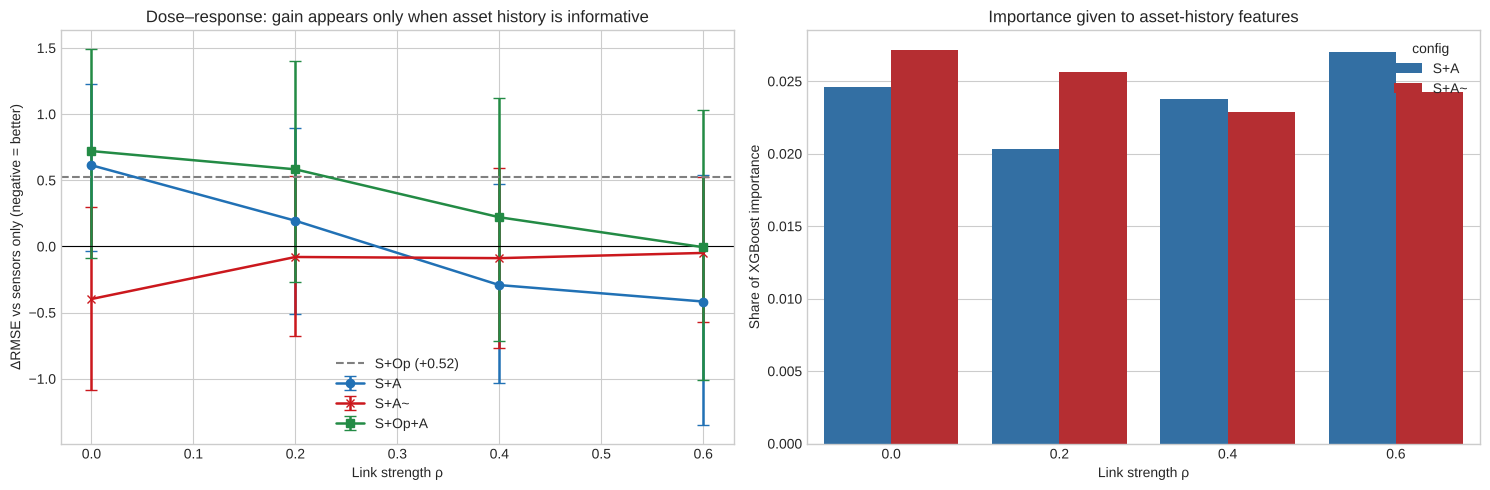

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ax = axes[0]
for cfg, color, marker in [('S+A', '#2171b5', 'o'), ('S+A~', '#cb181d', 'x'), ('S+Op+A', '#238b45', 's')]:
    s = STATS[(STATS.config == cfg) & (STATS.reference == 'S')].sort_values('rho')
    ax.errorbar(s.rho, s.dRMSE, yerr=[s.dRMSE - s.CI_low, s.CI_high - s.dRMSE],
                label=cfg, color=color, marker=marker, capsize=4, lw=1.8)
op = STATS[STATS.config == 'S+Op'].iloc[0]
ax.axhline(op.dRMSE, color='grey', ls='--', label=f"S+Op ({op.dRMSE:+.2f})")
ax.axhline(0, color='black', lw=0.8)
ax.set_xlabel('Link strength ρ'); ax.set_ylabel('ΔRMSE vs sensors only (negative = better)')
ax.set_title('Dose–response: gain appears only when asset history is informative')
ax.legend()

ax = axes[1]
s = IMP[IMP.config.isin(['S+A', 'S+A~'])]
sns.barplot(data=s, x='rho', y='asset_importance_share', hue='config', ax=ax, palette=['#2171b5', '#cb181d'])
ax.set_xlabel('Link strength ρ'); ax.set_ylabel('Share of XGBoost importance')
ax.set_title('Importance given to asset-history features')
plt.tight_layout()
plt.savefig(RESULTS_W11 / 'fig_dose_response.png', dpi=150)
plt.show()

## 7. Mechanism check — where does the gain occur?

Fleet records describe the engine's starting condition, so they should help most when sensors are least informative (healthy and mid-life) and add little near failure, where sensors dominate. A gain concentrated near failure would be suspicious.

ΔRMSE (S+A minus S) by life stage:


,ρ=0.0,ρ=0.2,ρ=0.4,ρ=0.6
stage,,,,
near failure (≤30),0.67,0.36,0.26,-0.28
mid-life (31–80),0.02,-0.62,-1.44,-1.59
early (>80),0.94,0.61,0.24,0.15


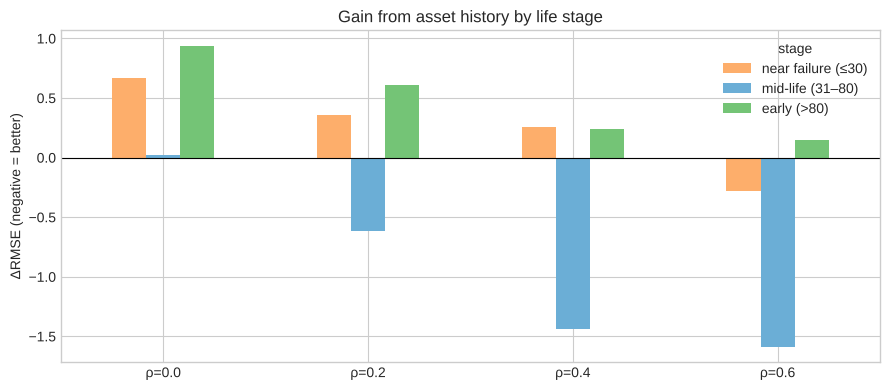

In [13]:
bins = [-1, 30, 80, RUL_MAX]
labels = ['near failure (≤30)', 'mid-life (31–80)', 'early (>80)']
ref = PRED[PRED.config == 'S'][['unit', 'cut_id', 'err', 'true_rul']].rename(columns={'err': 'err_S'})
mech = []
for rho in RHOS:
    m = PRED[(PRED.config == 'S+A') & (PRED.rho == rho)][['unit', 'cut_id', 'err']].merge(ref, on=['unit', 'cut_id'])
    m['stage'] = pd.cut(m.true_rul, bins=bins, labels=labels)
    g = m.groupby('stage').apply(lambda x: np.sqrt(np.mean(x.err ** 2)) - np.sqrt(np.mean(x.err_S ** 2)))
    mech.append(g.rename(f"ρ={rho}"))
MECH = pd.concat(mech, axis=1).round(2)
print("ΔRMSE (S+A minus S) by life stage:")
display(MECH)
MECH.T.plot(kind='bar', figsize=(9, 4), color=['#fdae6b', '#6baed6', '#74c476'])
plt.axhline(0, color='black', lw=0.8); plt.ylabel('ΔRMSE (negative = better)')
plt.title('Gain from asset history by life stage'); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(RESULTS_W11 / 'fig_gain_by_stage.png', dpi=150); plt.show()

## 8. Verdict

Automatic checklist. Falsification criteria:
- **F1** At ρ = 0, asset history gives no significant gain (it is pure noise).
- **F2** Shuffled asset history gives no significant gain at any ρ.
- **F3** The gain grows with ρ (dose–response, Spearman correlation between ρ and ΔRMSE < 0).
- **F4** The importance the model gives to asset features rises clearly with ρ (by more than 1 point of share from ρ = 0 to ρ = 0.6) and is higher than for shuffled data at ρ = 0.6.
- **F5** Near failure, the gain is no larger than in mid-life or early life (the gain does not come from end-of-life information).

In [14]:
sA  = STATS[(STATS.config == 'S+A') & (STATS.reference == 'S')].sort_values('rho')
sSh = STATS[(STATS.config == 'S+A~') & (STATS.reference == 'S')]
F1 = sA.loc[sA.rho == 0, 'p_holm'].iloc[0] >= 0.05
F2 = (sSh.p_holm >= 0.05).all()
F3 = stats.spearmanr(sA.rho, sA.dRMSE)[0] < 0
# Importance must clearly rise from rho=0 to rho=0.6 and exceed the shuffled control at rho=0.6
imp_real = IMP[IMP.config == 'S+A'].set_index('rho').asset_importance_share
imp_shuf = IMP[IMP.config == 'S+A~'].set_index('rho').asset_importance_share
F4 = (imp_real[max(RHOS)] - imp_real[0.0] > 0.01) and (imp_real[max(RHOS)] > imp_shuf[max(RHOS)])
near, rest = MECH.loc['near failure (≤30)'], MECH.drop('near failure (≤30)').min()
F5 = bool((near.iloc[1:] >= rest.iloc[1:] - 0.5).all())

checks = [
    ('Realism',  'R1 plausible distributions', R1),
    ('Realism',  'R2 batches overlap', R2),
    ('Realism',  'R3 moderate effect sizes', R3),
    ('Leakage',  'L1 static per engine', L1),
    ('Leakage',  'L2 no test/RUL access', L2),
    ('Leakage',  'L3 latent score never a feature', L3),
    ('Leakage',  'L4 folds disjoint by engine', L4),
    ('Leakage',  'L5 operational BI degradation-free', L5),
    ('Leakage',  'L6 information ceiling respected', L6),
    ('Falsification', 'F1 no gain at ρ = 0', F1),
    ('Falsification', 'F2 no gain when shuffled', F2),
    ('Falsification', 'F3 gain grows with ρ', F3),
    ('Falsification', 'F4 importance tracks ρ', F4),
    ('Mechanism', 'F5 gain not concentrated near failure', F5),
]
VERDICT = pd.DataFrame(checks, columns=['family', 'check', 'pass'])
VERDICT['result'] = VERDICT['pass'].map({True: 'PASS', False: 'FAIL'})
display(VERDICT[['family', 'check', 'result']])
VERDICT.to_csv(RESULTS_W11 / 'verdict.csv', index=False)

print("\nSummary of RMSE (5-fold CV, 300 truncation points):")
print(f"  S (sensors only)            {rmse_S:.2f}")
print(f"  S+Op (operational BI)       {STATS[STATS.config=='S+Op'].RMSE.iloc[0]:.2f}")
for _, r in sA.iterrows():
    sh = sSh[sSh.rho == r.rho].iloc[0]
    print(f"  ρ={r.rho:.1f}: S+A {r.RMSE:.2f} (Δ {r.dRMSE:+.2f}, {r.sig}) | shuffled {sh.RMSE:.2f} (Δ {sh.dRMSE:+.2f}, {sh.sig})")
print(f"\n{VERDICT['pass'].sum()}/{len(VERDICT)} checks passed")

# Outcome (separate from the checks: the checks can all pass with no gain at all)
sig_rhos = sA[(sA.p_holm < 0.05) & (sA.dRMSE < 0)].rho.tolist()
vs_shuf = STATS[(STATS.config == 'S+A') & (STATS.reference == 'S+A~') & (STATS.p_holm < 0.05) & (STATS.dRMSE < 0)].rho.tolist()
print("\nOUTCOME")
if sig_rhos:
    print(f"  Significant gain over sensors-only at ρ = {sig_rhos} (Holm-corrected Wilcoxon).")
else:
    print("  No significant gain over sensors-only at any ρ (Holm-corrected Wilcoxon).")
print(f"  Real history significantly better than shuffled at ρ = {vs_shuf if vs_shuf else 'none'}.")
print(f"  Largest gain: ΔRMSE = {sA.dRMSE.min():+.2f} at ρ = {sA.loc[sA.dRMSE.idxmin(), 'rho']}")

,family,check,result
0,Realism,R1 plausible distributions,PASS
1,Realism,R2 batches overlap,PASS
2,Realism,R3 moderate effect sizes,PASS
3,Leakage,L1 static per engine,PASS
4,Leakage,L2 no test/RUL access,PASS
5,Leakage,L3 latent score never a feature,PASS
6,Leakage,L4 folds disjoint by engine,PASS
7,Leakage,L5 operational BI degradation-free,PASS
8,Leakage,L6 information ceiling respected,PASS
9,Falsification,F1 no gain at ρ = 0,PASS



Summary of RMSE (5-fold CV, 300 truncation points):
  S (sensors only)            14.12
  S+Op (operational BI)       14.65
  ρ=0.0: S+A 14.74 (Δ +0.61, ns) | shuffled 13.72 (Δ -0.40, ns)
  ρ=0.2: S+A 14.32 (Δ +0.19, ns) | shuffled 14.04 (Δ -0.08, ns)
  ρ=0.4: S+A 13.83 (Δ -0.29, ns) | shuffled 14.03 (Δ -0.09, ns)
  ρ=0.6: S+A 13.71 (Δ -0.42, ns) | shuffled 14.07 (Δ -0.05, ns)

13/14 checks passed

OUTCOME
  No significant gain over sensors-only at any ρ (Holm-corrected Wilcoxon).
  Real history significantly better than shuffled at ρ = none.
  Largest gain: ΔRMSE = -0.42 at ρ = 0.6


In [15]:
# Copy results to Drive (Colab only)
if SAVE_DIR is not None:
    import shutil
    for f in RESULTS_W11.iterdir():
        shutil.copy(f, SAVE_DIR / f.name)
    print(f"Results copied to {SAVE_DIR}")

## 9. Interpretation guide

- **If F1–F5 pass:** the framework learns lifetime-relevant business information when it exists, and only then. The gain disappears at ρ = 0 and when histories are shuffled, so it comes from each engine's own record, not from noise or leakage. Report the dose–response curve, not a single ρ.
- **If F1 or F2 fail:** something other than the asset–lifetime link is driving the gain (chance correlation, overfitting). Do not report a gain; investigate first.
- **If F3 fails** (no gain even at ρ = 0.6): 100 engines may be too few to learn fleet effects from static records. Report this honestly; it is a realistic limitation for small fleets.
- **Relation to W10:** operational BI (S+Op) should remain at about 0, consistent with W10. Its value lies in the decision layer, not in prediction.